# Actividad asincrónica — Semana 6

**Capítulo 7: datos, estadística descriptiva y visualización** (unidades 34 a 37)

[Índice de la semana](semana-06.ipynb)

## Estado

**Entregada. Nota final: 100/100.**

## Cómo se califica

- 4 preguntas de 25 puntos cada una (100). No tiene pregunta adicional. La nota máxima es 100.
- Al entregar, la plataforma la califica pregunta por pregunta y muestra cuánto sacaste en cada una.
- Se puede corregir cualquier pregunta y volver a entregar hasta que el docente la revise: pulsar «Corregir mi entrega», cambiar lo necesario y entregar de nuevo; la nota que cuenta es la de la última entrega. Cuando el docente la revisa ya no se puede modificar, salvo que habilite otro intento.

## Cómo usar este notebook

Cada actividad trae la consigna, la guía de dónde se ve el tema, la **respuesta resuelta** (ya ejecutada, con su salida) y una explicación. Para entregar, copia el código de la respuesta en el recuadro de la plataforma y pulsa «Ejecutar». Las unidades 34 a 36 son de la semana 5: cada guía las enlaza y las explica en breve. La actividad 1 depende de la fecha de ejecución y la 4 necesita el archivo `ted.csv` junto al código.

## Checklist de entrega

- [x] Actividad 1 — Importación de módulos y su uso
- [x] Actividad 2 — Manejo de la biblioteca Pandas
- [x] Actividad 3 — Operaciones con DataFrames
- [x] Actividad 4 — Operaciones con DataFrames (ted.csv)
- [x] Revisar todo y pulsar «Entregar»

## Actividad 1 — Importación de módulos y su uso

### Consigna

Importe los módulos que le permitan trabajar con fechas y tiempo (módulo `datetime`). Use los diferentes métodos relacionados a operaciones con fechas y hora. En el siguiente apartado revise cada una de las fechas contenidas en la lista e imprima el número de semanas y los días restantes para llegar a esa fecha.

```python
# Espacio disponible para desarrollar el código y agregar los comentarios necesarios.
lista_de_fechas = ['04/01/2024', '01/28/2024', '03/16/2024', '05/24/2024', '07/30/2025']
```

### Guía

**Dónde se ve:** [Unidad 34](../semana-05/clase-2-modulos-y-pandas/u34-modulos-de-python.ipynb) (uso de módulos de Python, semana 5). En resumen: `import datetime` o `from datetime import datetime, date, timedelta` trae el módulo o sus clases; luego se usan como cualquier otra clase de la biblioteca estándar.

**Clave:** el formato de las fechas es **mes/día/año** (`%m/%d/%Y`), porque `'01/28/2024'` no puede ser día 01 del mes 28. Métodos usados: `datetime.strptime` (texto a fecha), `strftime` (fecha a texto), `date.today()`, `timedelta` (la resta de fechas devuelve uno) y `divmod` (cociente y resto a la vez).

**Error común:** usar `%Y-%m-%d`; con `'01/28/2024'` lanza `ValueError`.

### Respuesta

In [1]:
# Módulo datetime: trabaja con fechas y horas.
from datetime import date, datetime

lista_de_fechas = ['04/01/2024', '01/28/2024', '03/16/2024', '05/24/2024', '07/30/2025']

hoy = date.today()                                   # fecha de hoy
print("Hoy es:", hoy.strftime("%Y-%m-%d"))

for texto in lista_de_fechas:
    # El formato de las fechas es mes/día/año
    fecha = datetime.strptime(texto, "%m/%d/%Y").date()
    diferencia = fecha - hoy                         # resta de fechas: devuelve un timedelta
    dias = diferencia.days                           # número entero de días (negativo si ya pasó)
    semanas, restantes = divmod(abs(dias), 7)        # semanas completas y días que sobran
    texto_dias = f"{restantes} día" if restantes == 1 else f"{restantes} días"
    texto_semanas = f"{semanas} semana" if semanas == 1 else f"{semanas} semanas"

    if dias > 0:
        print(f"{fecha.strftime('%Y-%m-%d')}: faltan {texto_semanas} y {texto_dias}")
    elif dias == 0:
        print(f"{fecha.strftime('%Y-%m-%d')}: es hoy")
    else:
        print(f"{fecha.strftime('%Y-%m-%d')}: ya pasó hace {texto_semanas} y {texto_dias}")

Hoy es: 2026-11-15
2024-04-01: ya pasó hace 136 semanas y 6 días
2024-01-28: ya pasó hace 146 semanas y 0 días
2024-03-16: ya pasó hace 139 semanas y 1 día
2024-05-24: ya pasó hace 129 semanas y 2 días
2025-07-30: ya pasó hace 67 semanas y 4 días


**Explicación:** `strptime` convierte cada texto en fecha con el formato `%m/%d/%Y`; restar dos fechas da un `timedelta` y su atributo `.days` los días de diferencia; `divmod(dias, 7)` separa semanas completas y días restantes. Como todas las fechas de la lista son anteriores a hoy, el programa lo dice con claridad ("ya pasó hace...") en lugar de mostrar números negativos.

**Nota sobre el enunciado:** la salida depende del día en que se ejecute: **en la plataforma los números serán distintos** a los guardados aquí, que corresponden a la fecha real de esta ejecución. Si en algún momento la lista tuviera fechas futuras, el programa diría "faltan X semanas y Y días".

## Actividad 2 — Manejo de la biblioteca Pandas

### Consigna

Crear una serie de pandas, donde su índice esté compuesto por fechas y en la columna principal almacene los valores cargados en una lista. Graficar los valores de la lista en función de la fecha.

```python
precios = [140, 130, 120, 115, 160, 110, 170, 150, 157, 135]
```

### Guía

**Dónde se ve:** [Unidad 35](../semana-05/clase-2-modulos-y-pandas/u35-series-de-pandas.ipynb) (Serie de Pandas, semana 5). En resumen: una `pd.Series` es una columna de valores con un índice; si el índice es de tipo fecha, `pd.date_range` lo genera con un inicio, una cantidad de períodos (`periods`) y una frecuencia (`freq`, `'D'` es diaria). La serie se grafica con `matplotlib`. Las series con índice de fechas se profundizan en la [Unidad 38](clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb).

**Clave:** la serie y el índice deben tener la misma cantidad de elementos (10 y 10).

### Respuesta

2024-01-01    140
2024-01-02    130
2024-01-03    120
2024-01-04    115
2024-01-05    160
2024-01-06    110
2024-01-07    170
2024-01-08    150
2024-01-09    157
2024-01-10    135
Freq: D, Name: Precio, dtype: int64


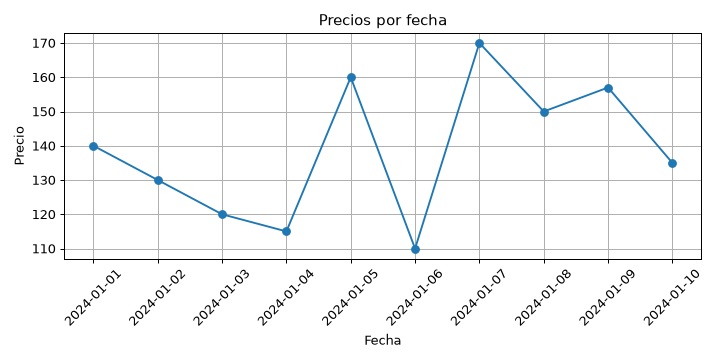

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

precios = [140, 130, 120, 115, 160, 110, 170, 150, 157, 135]

# Índice de fechas: 10 días consecutivos desde el 1 de enero de 2024
fechas = pd.date_range(start="2024-01-01", periods=len(precios), freq="D")

serie = pd.Series(precios, index=fechas, name="Precio")
print(serie)

# Gráfica de los valores en función de la fecha
plt.figure(figsize=(8, 4))
plt.plot(serie.index, serie.values, marker="o")
plt.title("Precios por fecha")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Explicación:** `pd.date_range` crea 10 fechas diarias, `pd.Series(precios, index=fechas)` las une con los valores y `plt.plot` dibuja el precio (eje vertical) en función de la fecha (eje horizontal), con título, etiquetas y marcadores. Alternativa equivalente: `serie.plot(marker='o')`.

**Nota sobre la plataforma:** si el recuadro no muestra la gráfica, la tabla impresa con `print(serie)` sigue demostrando que la serie con índice de fechas está bien construida.

## Actividad 3 — Operaciones con DataFrames

### Consigna

Dado el siguiente diccionario construya un objeto DataFrame. Filtre los resultados por año de publicación. Obtenga algunas columnas basado en que contenga alguna palabra en el nombre de la publicación.

```python
publicaciones_literarias = {
    1605: "Don Quijote de la Mancha - Miguel de Cervantes",
    1865: "Alicia en el país de las maravillas - Lewis Carroll",
    1949: "1984 - George Orwell",
    1954: "El Señor de los Anillos - J.R.R. Tolkien",
    1997: "Harry Potter y la piedra filosofal - J.K. Rowling",
    2003: "El Código Da Vinci - Dan Brown"
}
```

### Guía

**Dónde se ve:** [Unidad 36](../semana-05/clase-2-modulos-y-pandas/u36-dataframes-de-pandas.ipynb) (Pandas DataFrame, semana 5). En resumen: un `DataFrame` se construye desde un diccionario o una lista de pares; se filtra con una **máscara booleana** (`df[df['año'] > 1900]`) y las columnas de texto tienen el accesor `.str` (`str.contains`, `str.split`). El orden de los resultados se trata en la [Unidad 37](clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb).

**Nota sobre el enunciado:** "obtenga algunas columnas basado en que contenga alguna palabra en el nombre de la publicación" en realidad pide **filas** (publicaciones) cuyo título contiene una palabra; las columnas son solo `año` y `publicación`. Se resuelve de esa forma y, además, se muestra `filter(like=...)`, que sí selecciona columnas por una palabra en el nombre de la columna.

### Respuesta

In [3]:
import pandas as pd

publicaciones_literarias = {
    1605: "Don Quijote de la Mancha - Miguel de Cervantes",
    1865: "Alicia en el país de las maravillas - Lewis Carroll",
    1949: "1984 - George Orwell",
    1954: "El Señor de los Anillos - J.R.R. Tolkien",
    1997: "Harry Potter y la piedra filosofal - J.K. Rowling",
    2003: "El Código Da Vinci - Dan Brown"
}

# 1. DataFrame con dos columnas: año y publicación
df = pd.DataFrame(list(publicaciones_literarias.items()), columns=["año", "publicación"])

# Opcional: separar el título y el autor (están unidos por " - ")
df[["título", "autor"]] = df["publicación"].str.split(" - ", expand=True)
print(df)

# 2. Filtrar por año de publicación (máscara booleana)
print("\nPublicados después de 1950:")
print(df[df["año"] > 1950])

print("\nPublicados entre 1800 y 1960:")
print(df[(df["año"] >= 1800) & (df["año"] <= 1960)])

# 3. Filtrar por una palabra contenida en el nombre de la publicación
print("\nTítulos que contienen 'de la':")
print(df[df["publicación"].str.contains("de la", case=False, regex=False)][["año", "título"]])

print("\nTítulos que contienen 'Anillos' o 'Potter':")
print(df[df["título"].str.contains("Anillos|Potter", case=False)][["año", "título"]])

# Si se leyera literalmente "columnas": filter(like=...) elige columnas cuyo nombre contiene la palabra
print("\nColumnas cuyo nombre contiene 'pub':")
print(df.filter(like="pub"))

    año  ...                autor
0  1605  ...  Miguel de Cervantes
1  1865  ...        Lewis Carroll
2  1949  ...        George Orwell
3  1954  ...       J.R.R. Tolkien
4  1997  ...         J.K. Rowling
5  2003  ...            Dan Brown

[6 rows x 4 columns]

Publicados después de 1950:
    año  ...           autor
3  1954  ...  J.R.R. Tolkien
4  1997  ...    J.K. Rowling
5  2003  ...       Dan Brown

[3 rows x 4 columns]

Publicados entre 1800 y 1960:
    año  ...           autor
1  1865  ...   Lewis Carroll
2  1949  ...   George Orwell
3  1954  ...  J.R.R. Tolkien

[3 rows x 4 columns]

Títulos que contienen 'de la':
    año                               título
0  1605             Don Quijote de la Mancha
1  1865  Alicia en el país de las maravillas

Títulos que contienen 'Anillos' o 'Potter':
    año                              título
3  1954             El Señor de los Anillos
4  1997  Harry Potter y la piedra filosofal

Columnas cuyo nombre contiene 'pub':
                      

**Explicación:** `pd.DataFrame(list(dic.items()), columns=[...])` convierte cada par clave-valor en una fila. El filtro por año usa una máscara booleana (`&` para combinar condiciones, con paréntesis). El filtro por palabra usa `str.contains`, que devuelve `True` o `False` por fila; con `regex=False` el texto se busca literal y con `Anillos|Potter` (regex) se buscan varias palabras. `str.split(' - ', expand=True)` separa título y autor en dos columnas.

## Actividad 4 — Operaciones con DataFrames (ted.csv)

### Consigna

Descargue el archivo `ted.csv` del siguiente link: https://www.kaggle.com/datasets/rounakbanik/ted-talks y guárdelo en el mismo directorio donde está localizado el notebook. Lea el archivo csv como un dataframe. Muestre la cabecera o las primeras filas del DataFrame. Verifique el tipo de datos contenido en cada una de las columnas. Verifique el número de registros perdidos. En una columna adicional calcule el número de comentarios entre el número de vistas.

### Guía

**Dónde se ve:** [Unidad 36](../semana-05/clase-2-modulos-y-pandas/u36-dataframes-de-pandas.ipynb) (Pandas DataFrame, semana 5) para `read_csv`, `head()` y `dtypes`; los valores faltantes y las operaciones entre columnas se retoman en las [Unidad 37](clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb), [Unidad 38](clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb). `isnull().sum()` cuenta los faltantes por columna y un segundo `.sum()` da el total.

**Cómo obtener el archivo:**

- En Kaggle (requiere iniciar sesión) el conjunto de datos *TED Talks* trae `ted_main.csv`: descárguelo y renómbrelo a `ted.csv`.
- Copia pública con el mismo contenido y nombre: https://raw.githubusercontent.com/justmarkham/pycon-2019-tutorial/master/ted.csv (tutorial de pandas de Kevin Markham, PyCon 2019). Esa copia es la que está guardada junto a este notebook, en `ted.csv`.
- En la plataforma el archivo debe estar subido o disponible en la misma carpeta que el código, o `pd.read_csv('ted.csv')` fallará con `FileNotFoundError`. Alternativa: pasar directamente la dirección pública a `read_csv`, siempre que la plataforma permita acceso a internet.

**Error común:** dividir antes de verificar que `views` no tenga ceros ni faltantes: la división da `inf` o `NaN` en esas filas (aquí no hay vistas en cero).

### Respuesta

In [4]:
import pandas as pd

# 1. Leer el archivo csv (debe estar en la misma carpeta que el notebook)
df = pd.read_csv("ted.csv")
print("Filas y columnas:", df.shape)

# 2. Cabecera o primeras filas
print("\nPrimeras filas:")
print(df.head())

# 3. Tipo de dato de cada columna
print("\nTipos de datos:")
print(df.dtypes)

# 4. Registros perdidos (valores faltantes) por columna y en total
print("\nValores faltantes por columna:")
print(df.isnull().sum())
print("Total de valores faltantes:", df.isnull().sum().sum())

# 5. Columna adicional: comentarios entre vistas
df["comentarios_por_vista"] = df["comments"] / df["views"]
print("\nComentarios por vista (primeras filas):")
print(df[["title", "comments", "views", "comentarios_por_vista"]].head())

Filas y columnas: (2550, 17)

Primeras filas:
   comments  ...     views
0      4553  ...  47227110
1       265  ...   3200520
2       124  ...   1636292
3       200  ...   1697550
4       593  ...  12005869

[5 rows x 17 columns]

Tipos de datos:
comments              int64
description             str
duration              int64
event                   str
film_date             int64
languages             int64
main_speaker            str
name                    str
num_speaker           int64
published_date        int64
ratings                 str
related_talks           str
speaker_occupation      str
tags                    str
title                   str
url                     str
views                 int64
dtype: object

Valores faltantes por columna:
comments              0
description           0
duration              0
event                 0
film_date             0
languages             0
main_speaker          0
name                  0
num_speaker           0
published_date

**Explicación:** `read_csv` carga el archivo (2.550 charlas y 17 columnas); `head()` muestra las primeras cinco filas; `dtypes` indica que `comments`, `duration`, `film_date`, `languages`, `num_speaker`, `published_date` y `views` son enteros y el resto texto; `isnull().sum()` muestra que los únicos faltantes están en `speaker_occupation` (el total aparece en la salida) y `df['comments'] / df['views']` crea la columna nueva operando elemento por elemento.

**Nota sobre el enunciado:** el enlace de Kaggle contiene `ted_main.csv`, no `ted.csv`; hay que renombrarlo o usar la copia pública. Los tipos de texto aparecen como `object` o `str` según la versión de pandas.

[Índice de la semana](semana-06.ipynb)